(pysat-nonogram)=
# 解数织：用位置变量把 CNF 变小

## 本章的内容

本章用 SAT 解数织，主角是 CNF 如何造得更小。

- 由一行的提示，列出全部可能的涂法，这是一个递归的过程
- 把候选原样写成 CNF，组合会爆炸，速度随之变慢
- 把每个数字的起始位置做成变量，CNF 会小得多，求解也快得多

最后还要解一道 45×60 的大型题目。

## 数织的规则

数织是以数字为线索涂格的谜题。

- 盘面是正方形的网格，每一格涂黑或留白
- 行左边的数字，是该行连续黑格的长度按顺序排成的
- 列上方或下方的数字也是同样
- 所有黑格确定之后，题目就完成了

![数织游戏](images/nonogram01.png)

把每一格用“涂黑则为真”的布尔变量表示，再把行与列的提示写成约束。

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import itertools

## 列出一行的全部解

`paint_numbers(numbers, count)` 造出把 `numbers` 的数字排进长度为 `count` 的一行中的所有涂法，涂的格记作 `1`，不涂的格记作 `-1`。

这可以用递归写出，终止条件有两个。

1. 排下这些数字所需的格数超过 `count`，此时无解，例如 `[2, 1, 5]` 至少需要 2+1+5+2 = 10 格
2. 只剩最后一个数字，此时把该长度的方块放在所有可以放置的位置上

若不属于上述两种，就分两个方向分支。

3. 把第一个数字放在这里，其余部分递归求解，即涂 `numbers[0]` 格，再空出一格
4. 这一格留白，其余部分递归求解

In [2]:
def paint_numbers(numbers, count):
    """返回把 numbers 的数字排在宽度 count 里的所有涂法（1=黑, -1=白）"""
    if sum(numbers) + len(numbers) - 1 > count:
        return                      # 1. 格子不够

    if len(numbers) == 1:
        n = numbers[0]
        for i in range(count - n + 1):          # 2. 最后一个数字放在所有能放的位置
            yield [-1] * i + [1] * n + [-1] * (count - i - n)
        return

    # 3. 把开头的数字放在当前位置（后面空 1 个格子）
    for rest in paint_numbers(numbers[1:], count - numbers[0] - 1):
        yield [1] * numbers[0] + [-1] + rest

    # 4. 空出这个格子，向右挪一格
    for rest in paint_numbers(numbers, count - 1):
        yield [-1] + rest

下面是把 `[2, 1, 5]` 排进 12 格的例子，为便于阅读，把 `-1` 显示成 `0`。

In [3]:
for line in paint_numbers([2, 1, 5], 12):
    print([int(x > 0) for x in line])

[1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0]
[1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]
[1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1]
[1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0]
[1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1]
[1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1]
[0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0]
[0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1]
[0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1]
[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1]


共有 9 种涂法。人一行一行看，能看出“这一格必定是黑的”，而 SAT 求解器必须把全部候选都告诉它。

## 从 DNF 变到 CNF

`paint_numbers()` 返回的每一种涂法，都是这一格涂黑、那一格留白这样的 AND 条件，而这些项再用 OR 连起来，因此它是 DNF，即析取范式。SAT 求解器只能解 CNF，即合取范式，因此需要转换。

用分配律把 DNF 直接变成 CNF，式子会爆炸，因此引入新的变量。例如 A、B、C 之中恰好一个为假这个 DNF

$$
(\neg A \wedge B \wedge C) \vee (A \wedge \neg B \wedge C) \vee (A \wedge B \wedge \neg C)
$$

给每一项各分配一个新变量 X、Y、Z，再用等价关系 $\Leftrightarrow$ 连接。

$$
(X \vee Y \vee Z) \wedge (X \Leftrightarrow \neg A \wedge B \wedge C) \wedge (Y \Leftrightarrow A \wedge \neg B \wedge C) \wedge (Z \Leftrightarrow A \wedge B \wedge \neg C)
$$

$P \Leftrightarrow Q$ 可以写成 CNF

$$
(\neg P \vee Q) \wedge (P \vee \neg Q)
$$

把它套到 $X \Leftrightarrow (\neg A \wedge B \wedge C)$ 上，就得到下面四个子句。

$$
(\neg X \vee \neg A) \wedge (\neg X \vee B) \wedge (\neg X \vee C) \wedge (X \vee A \vee \neg B \vee \neg C)
$$

下面用 SymPy 确认。

In [4]:
from sympy import symbols, Equivalent
from sympy.logic.boolalg import to_cnf

X, A, B, C = symbols("X A B C")
to_cnf(Equivalent(X, ~A & B & C))

(B | ~X) & (C | ~X) & (~A | ~X) & (A | X | ~B | ~C)

结果与上式同形，只是子句的顺序不同，这种转换称为 Tseitin 变换，好处是能把式子的长度控制住。

`dnf_to_cnf(dnf)` 给 DNF 的每一项分配一个新变量，并造出上面那四个子句。

- 对每一项造一个新变量 `z`
- `z → 各个文字`，即造出 `[-z, v]`，其中 v 是项中含有的变量
- `项 → z`，即造出 `[z] + [-v for v in term]`
- 最后造一个把所有 `z` 用 OR 连起来的子句

新变量的编号必须大于已有变量的最大编号，把 `new_vars` 传进去，它就会用该编号之后的部分。

In [5]:
def dnf_to_cnf(dnf, new_vars=None):
    """用 Tseitin 变换把 DNF 变成 CNF"""
    if new_vars is None:
        # 使用现有变量最大编号之后的编号
        start = max(max(map(abs, term)) for term in dnf) + 1
        new_vars = iter(range(start, start + len(dnf)))

    zlist = []      # 新变量的列表
    cnf = []
    for term in dnf:
        z = next(new_vars)
        zlist.append(z)
        cnf.append([z] + [-v for v in term])   # 是项则为 z（项 → z）
        for v in term:
            cnf.append([-z, v])                # z 则为各文字（z → 文字）
    cnf.append(zlist)                          # z 中至少一个为真
    return cnf

下面用三个变量中恰好一个为假的 DNF 试一次，请读者确认得到的解确实是恰好一个为假，而 `enum_models()` 返回满足条件的全部解，可以直接对照。

In [6]:
from pprint import pprint
from pysat.solvers import Solver

dnf = [[-1, 2, 3], [1, -2, 3], [1, 2, -3]]
cnf = dnf_to_cnf(dnf)

print("CNF")
pprint(cnf)

print("solutions")
sat = Solver()
sat.append_formula(cnf)
for sol in sat.enum_models():
    print([int(x > 0) for x in sol])

CNF
[[4, 1, -2, -3],
 [-4, -1],
 [-4, 2],
 [-4, 3],
 [5, -1, 2, -3],
 [-5, 1],
 [-5, -2],
 [-5, 3],
 [6, -1, -2, 3],
 [-6, 1],
 [-6, 2],
 [-6, -3],
 [4, 5, 6]]
solutions
[0, 1, 1, 1, 0, 0]
[1, 0, 1, 0, 1, 0]
[1, 1, 0, 0, 0, 1]


新变量 4、5、6 增加了，而最初三个变量即原有变量中，每个解都只有一个为假。

也可以试试与 `paint_numbers()` 的结果是否一致，DNF 的解与转成 CNF 之后解出的结果应当是同一个集合。

In [7]:
n = 12
solutions = list(paint_numbers([2, 1, 5], n))
variables = list(range(1, n + 1))

# 把涂法变成 DNF（变量编号 × 1 或 -1）
dnf = [[v * t for v, t in zip(variables, term)] for term in solutions]

sat = Solver()
sat.append_formula(dnf_to_cnf(dnf))
# 只取出 n 个变量，把符号统一成 -1/1
solutions_cnf = [[x // abs(x) for x in res[:n]] for res in sat.enum_models()]

print(sorted(solutions) == sorted(solutions_cnf))

True


## 解数织的朴素做法

由行与列的提示直接造出 CNF。

1. 给每一格分配一个布尔变量，编号 1 到宽乘高
2. 为转换所需的新变量准备编号
3. 对每一行与每一列分别用 `paint_numbers()` 造出 DNF，转成 CNF 之后加入
4. 用 `Solver` 求解，再还原成 `(高度, 宽度)` 的形状
5. 用 `plot()` 画出来

In [8]:
class NonogramSimpleSolver:
    """把提示直接变成 CNF 的朴素求解器"""

    def __init__(self, rows, cols, width=None, height=None):
        if width is None:
            width = len(cols)
        if height is None:
            height = len(rows)
        self.rows = rows
        self.cols = cols
        self.width = width
        self.height = height
        self.var_count = width * height

        # 各格子的变量（按行排的二维数组）
        self.vars = np.arange(1, self.var_count + 1).reshape(-1, width)
        # 转换用的新变量编号（从格子变量的下一个编号开始）
        self.new_vars = itertools.count(self.var_count + 1)

        self.cnf = []
        for i, row in enumerate(rows):
            self.add_constraints(row, width, self.vars[i, :].tolist())
        for j, col in enumerate(cols):
            self.add_constraints(col, height, self.vars[:, j].tolist())

    def add_constraints(self, numbers, count, variables):
        """把 1 行（或 1 列）的提示转换成 CNF 并追加"""
        dnf = []
        for pattern in paint_numbers(numbers, count):
            dnf.append([v * p for v, p in zip(variables, pattern)])
        self.cnf.extend(dnf_to_cnf(dnf, new_vars=self.new_vars))

    def solve(self):
        sat = Solver()
        sat.append_formula(self.cnf)
        if not sat.solve():
            raise ValueError("没有找到解")
        model = sat.get_model()
        solution = np.sign(np.array(model[:self.var_count])).reshape(self.height, self.width)
        self.solution = (solution + 1) // 2      # 把 -1/1 换成 0/1
        return self.solution

    def plot(self, font_size=9):
        from helper.plot import plot_nonogram_board
        return plot_nonogram_board({"rows": self.rows, "cols": self.cols},
                                   self.solution, font_size=font_size)

下面解一道小题目看看。

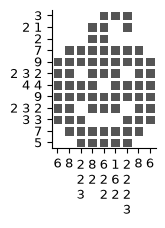

In [9]:
rows = [
    [3],
    [2, 1],
    [2],
    [7],
    [9],
    [2, 3, 2],
    [4, 4],
    [9],
    [2, 3, 2],
    [3, 3],
    [7],
    [5]
]

cols = [
    [6],
    [8],
    [2, 2, 3],
    [8, 2],
    [6, 2, 2],
    [1, 6, 2],
    [2, 2, 2, 3],
    [8],
    [6]
]

pbn = NonogramSimpleSolver(rows, cols)
pbn.solve()
pbn.plot();

## 从文件读入再求解

`solve_and_paint(fn, solver)` 用 `solver` 解开 JSON 文件中的题目并画出来。

`````{admonition} 数织谜题的网站
:class: tip
https://www.nonograms.org/nonograms

用 `helper.puzzle.extract_nonogram()` 可以取得这个网站上的数织盘面。打开浏览器的开发者工具，把表示盘面的 `<table>` 标签复制下来，交给这个函数执行，就会返回表示盘面的字典。
`````

In [10]:
import json


def solve_and_paint(fn, solver, font_size=9):
    if isinstance(fn, dict):
        data = fn
    else:
        with open(fn) as f:
            data = json.load(f)

    pbn = solver(data["rows"], data["cols"])
    pbn.solve()
    pbn.plot(font_size=font_size)

下面解 `nonogram02.json`，并计时。

CPU times: total: 8.67 s
Wall time: 8.97 s


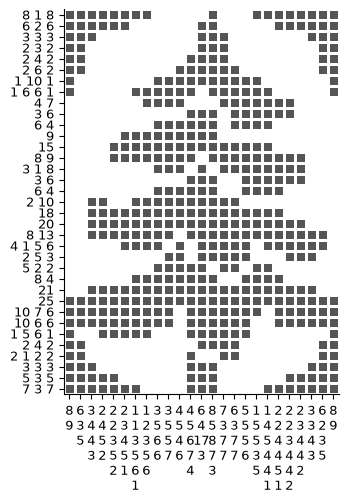

In [11]:
%time solve_and_paint("data/nonogram02.json", solver=NonogramSimpleSolver)

花了十秒以上，原因是格数一多，每一行的涂法候选就迅速增加，CNF 的子句数也随之爆炸。

## 用位置变量提速

DNF 到 CNF 的转换会按候选的个数造出新变量与子句，例如数字为 `[1, 2, 3, 2, 1]`、宽度为 30 时，涂法多达 26,334 种。

In [12]:
len(list(paint_numbers([1, 2, 3, 2, 1], 30)))

26334

为了避免这种组合爆炸，改为把每个数字的起始位置做成变量。

要在宽度 10 里放 `[1, 2, 3]`，数字 1 的起始位置只有 0、1、2 三种。不去数涂法的候选，而数每个数字从哪里开始，这正是这一步的关键。

`create_position_variables(numbers, count, new_bool_variables)` 对每个数字造出 `{起始位置: 变量编号}` 的字典。

- `start_pos()`：把数字紧挨着排下时，各数字的起始位置
- `end_pos()`：右端对齐时，各数字的起始位置，也就是可以放置的最大起始位置

例如把 `[1, 2, 3]` 放进宽度 10 时，数字 3 的起始位置是 5〜7。

In [13]:
def start_pos(numbers, count):
    """靠左排列时各数字的起始位置"""
    s = 0
    for n in numbers:
        yield s
        s += n + 1


def end_pos(numbers, count):
    """靠右对齐时各数字的起始位置（= 能放的最大起始位置）"""
    width = sum(numbers) + len(numbers) - 1
    start = count - width
    for pos in start_pos(numbers, count):
        yield start + pos


def create_position_variables(numbers, count, new_bool_variables):
    """生成 {起始位置: 变量编号} 的列表"""
    pos_variables = []
    for a, b in zip(start_pos(numbers, count), end_pos(numbers, count)):
        pos_variables.append({j: next(new_bool_variables) for j in range(a, b + 1)})
    return pos_variables


numbers = [1, 2, 3]
count = 10
pos_variables = create_position_variables(numbers, count, itertools.count(1))
pos_variables

[{0: 1, 1: 2, 2: 3}, {2: 4, 3: 5, 4: 6}, {5: 7, 6: 8, 7: 9}]

数字 1 可以从 0〜2 开始，数字 2 从 2〜4，数字 3 从 5〜7 开始，请读者与 `paint_numbers()` 的候选对照。

In [14]:
for line in paint_numbers([1, 2, 3], 10):
    print([int(x > 0) for x in line])

[1, 0, 1, 1, 0, 1, 1, 1, 0, 0]
[1, 0, 1, 1, 0, 0, 1, 1, 1, 0]
[1, 0, 1, 1, 0, 0, 0, 1, 1, 1]
[1, 0, 0, 1, 1, 0, 1, 1, 1, 0]
[1, 0, 0, 1, 1, 0, 0, 1, 1, 1]
[1, 0, 0, 0, 1, 1, 0, 1, 1, 1]
[0, 1, 0, 1, 1, 0, 1, 1, 1, 0]
[0, 1, 0, 1, 1, 0, 0, 1, 1, 1]
[0, 1, 0, 0, 1, 1, 0, 1, 1, 1]
[0, 0, 1, 0, 1, 1, 0, 1, 1, 1]


## 位置变量的约束

位置变量需要两类约束。

1. 每个数字的起始位置在候选中恰好一个
2. 设数字 `i` 的起始位置为 `p1`、下一个数字的起始位置为 `p2`，则要求 `p2 >= p1 + num[i] + 1`，即至少空出一格

第 2 条可以写成 `[-p1_var, -p2_var]` 这样的子句，即 `p1` 与 `p2` 的组中间隔不足的组合不能同时为真。

`only_one_true()` 负责恰好一个，`pairwise()` 是把相邻元素两两配对的辅助函数。

In [15]:
def only_one_true(variables):
    """变量中恰好一个为 True 的 CNF"""
    yield list(variables)                     # 至少一个
    for i, j in itertools.combinations(variables, 2):
        yield [-i, -j]                        # 两个同时不行


def pairwise(iterable):
    """生成 (a0,a1), (a1,a2), ..."""
    a, b = itertools.tee(iterable)
    next(b, None)
    return zip(a, b)


def position_variables_constraint(pos_variables, numbers):
    cnf = []

    # 1. 每个数字的起始位置只有一个
    for pos_var in pos_variables:
        cnf.extend(only_one_true(pos_var.values()))

    # 2. 相邻数字要分开，不能重叠
    for i, (pos_var1, pos_var2) in enumerate(pairwise(pos_variables)):
        gap = numbers[i] + 1
        for pos1, pos2 in itertools.product(pos_var1, pos_var2):
            if pos2 < pos1 + gap:
                cnf.append([-pos_var1[pos1], -pos_var2[pos2]])
    return cnf


cnf = position_variables_constraint(pos_variables, numbers)
cnf

[[1, 2, 3],
 [-1, -2],
 [-1, -3],
 [-2, -3],
 [4, 5, 6],
 [-4, -5],
 [-4, -6],
 [-5, -6],
 [7, 8, 9],
 [-7, -8],
 [-7, -9],
 [-8, -9],
 [-2, -4],
 [-3, -4],
 [-3, -5],
 [-5, -7],
 [-6, -7],
 [-6, -8]]

下面把 `cnf` 解出来，再还原成格的涂法。

- 起始位置的变量为真，就从该位置起把该数字涂 `num[i]` 格
- `cell_map` 是变量编号到起始位置与数字的对应表

In [16]:
sat = Solver()
sat.append_formula(cnf)

cell_map = {}
for n, pos_var in zip(numbers, pos_variables):
    for pos, var in pos_var.items():
        cell_map[var] = (pos, n)

for sol in sat.enum_models():
    cells = [0] * count
    for var, v in enumerate(sol, 1):
        if v > 0:
            pos, n = cell_map[var]
            for j in range(pos, pos + n):
                cells[j] = 1
    print(cells)

[1, 0, 1, 1, 0, 1, 1, 1, 0, 0]
[1, 0, 1, 1, 0, 0, 1, 1, 1, 0]
[1, 0, 1, 1, 0, 0, 0, 1, 1, 1]
[1, 0, 0, 0, 1, 1, 0, 1, 1, 1]
[0, 0, 1, 0, 1, 1, 0, 1, 1, 1]
[0, 1, 0, 0, 1, 1, 0, 1, 1, 1]
[0, 1, 0, 1, 1, 0, 1, 1, 1, 0]
[1, 0, 0, 1, 1, 0, 1, 1, 1, 0]
[1, 0, 0, 1, 1, 0, 0, 1, 1, 1]
[0, 1, 0, 1, 1, 0, 0, 1, 1, 1]


得到了同样的 10 种涂法，与 `paint_numbers()` 相比，变量与子句都少得多。

## 把格变量与位置变量连起来

到此为止只是决定了一行之内的位置，而数织中行与列共用同一批格，因此要追加约束，把格变量与位置变量连接起来。

格 `j` 与位置的关系有下面四种。

1. 第一个方块之前的格是白的，即 `pos[0]` 之前 `cell = 0`
2. 最后一个方块之后的格是白的，即 `pos[-1] + num[-1]` 之后 `cell = 0`
3. 方块之内是黑的，即 `pos[i] <= j < pos[i] + num[i]` 时 `cell = 1`
4. 方块之间是白的，即 `pos[i] + num[i] <= j < pos[i+1]` 时 `cell = 0`

这些都可以用“位置变量为真，则格变量如此”的蕴含写出，例如 `-pos_var, cell_var`。

In [17]:
def cell_variables_constraint(pos_variables, cell_variables, numbers, count):
    cnf = []

    # 3. 块之中是黑
    for i, pos_var in enumerate(pos_variables):
        for pos, var in pos_var.items():
            for j in range(numbers[i]):
                cnf.append([-var, cell_variables[pos + j]])

    # 1. 第一个块之前是白
    for pos, var in pos_variables[0].items():
        for j in range(pos):
            cnf.append([-var, -cell_variables[j]])

    # 2. 最后一个块之后是白
    for pos, var in pos_variables[-1].items():
        for j in range(pos + numbers[-1], count):
            cnf.append([-var, -cell_variables[j]])

    # 4. 块之间是白
    for i, (pos_var1, pos_var2) in enumerate(pairwise(pos_variables)):
        for pos1, pos2 in itertools.product(pos_var1, pos_var2):
            if pos2 > pos1 + numbers[i]:
                for j in range(pos1 + numbers[i], pos2):
                    cnf.append([-pos_var1[pos1], -pos_var2[pos2], -cell_variables[j]])
    return cnf

下面用 10 格与 `[1, 2, 3]`，把全部约束合起来求解。`cell_variables` 是格的变量，编号 1 到 10，位置变量从它后面的编号开始。

In [18]:
numbers = [1, 2, 3]
count = 10

cell_variables = list(range(1, count + 1))
pos_variables = create_position_variables(numbers, count, itertools.count(count + 1))

cnf = position_variables_constraint(pos_variables, numbers)
cnf += cell_variables_constraint(pos_variables, cell_variables, numbers, count)

sat = Solver()
sat.append_formula(cnf)
for sol in sat.enum_models():
    print([int(x > 0) for x in sol[:count]])

[1, 0, 1, 1, 0, 1, 1, 1, 0, 0]
[1, 0, 1, 1, 0, 0, 1, 1, 1, 0]
[1, 0, 1, 1, 0, 0, 0, 1, 1, 1]
[1, 0, 0, 1, 1, 0, 0, 1, 1, 1]
[0, 1, 0, 1, 1, 0, 0, 1, 1, 1]
[0, 1, 0, 1, 1, 0, 1, 1, 1, 0]
[1, 0, 0, 1, 1, 0, 1, 1, 1, 0]
[1, 0, 0, 0, 1, 1, 0, 1, 1, 1]
[0, 1, 0, 0, 1, 1, 0, 1, 1, 1]
[0, 0, 1, 0, 1, 1, 0, 1, 1, 1]


得到了与 `paint_numbers()` 相同的涂法，这样即使行与列分别造约束，也能通过共用的格变量保持一致。

## 更快的求解器

`NonogramFastSolver` 继承 `NonogramSimpleSolver`，只替换了 `add_constraints()`。

In [19]:
class NonogramFastSolver(NonogramSimpleSolver):
    """使用位置变量的快速求解器"""

    def add_constraints(self, numbers, count, cell_variables):
        pos_variables = create_position_variables(numbers, count, self.new_vars)
        self.cnf.extend(position_variables_constraint(pos_variables, numbers))
        self.cnf.extend(cell_variables_constraint(pos_variables, cell_variables,
                                                 numbers, count))

下面解同一道题目，比较两者的耗时。

CPU times: total: 109 ms
Wall time: 108 ms


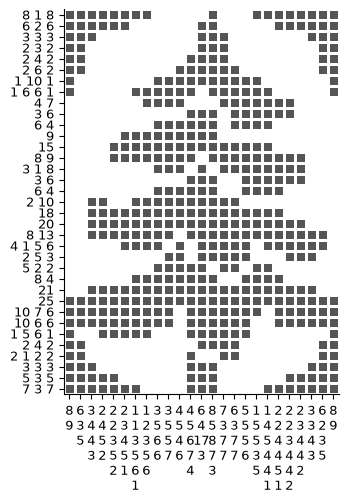

In [20]:
%time solve_and_paint("data/nonogram02.json", solver=NonogramFastSolver)

用 `NonogramSimpleSolver` 要十秒以上的题目，换成新的求解器之后不到一秒就解出了，原因在于不再把全部候选涂法做成 CNF，而只把起始位置做成变量，式子小了一个数量级。

最后再解一道 45×60 的大型题目。

CPU times: total: 1.7 s
Wall time: 1.77 s


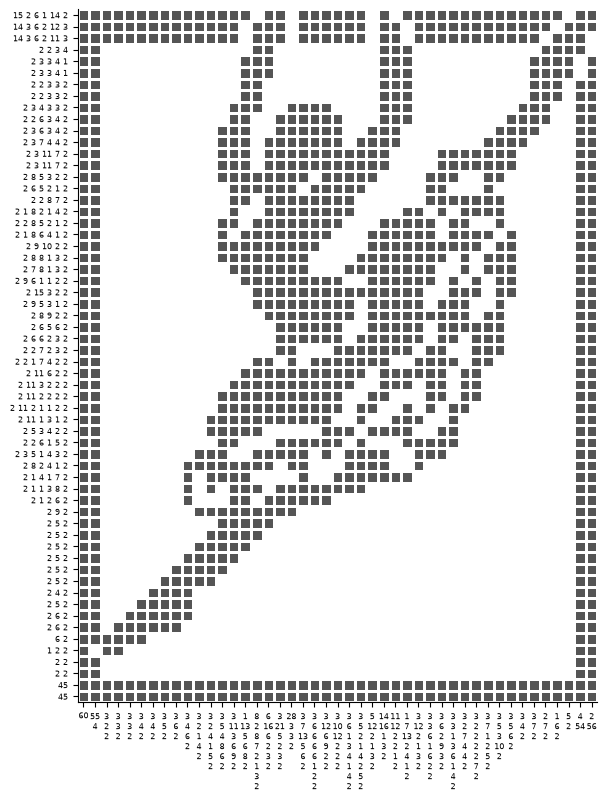

In [21]:
%time solve_and_paint("data/nonogram03.json", solver=NonogramFastSolver, font_size=6)

## 验算

确认解出的盘面是否真的与提示一致，做法是数出连续黑格的长度，再与行、列的提示比较。

In [22]:
def runs(line):
    """从一行中依次取出连续 1 的长度"""
    result, n = [], 0
    for x in line:
        if x:
            n += 1
        elif n:
            result.append(n)
            n = 0
    if n:
        result.append(n)
    return result


def check_nonogram(rows, cols, solution):
    ok_rows = [runs(solution[i]) for i in range(len(rows))] == [list(r) for r in rows]
    ok_cols = [runs(solution[:, j]) for j in range(len(cols))] == [list(c) for c in cols]
    return ok_rows and ok_cols


print("小谜题:", check_nonogram(rows, cols, pbn.solution))

with open("data/nonogram02.json") as f:
    data02 = json.load(f)
pbn02 = NonogramFastSolver(data02["rows"], data02["cols"])
pbn02.solve()
print("nonogram02 :", check_nonogram(data02["rows"], data02["cols"], pbn02.solution))

小谜题: True
nonogram02 : True


## 小结

- 一行的提示可以用 `paint_numbers()` 展开成全部涂法
- 原样写成 CNF，子句会按候选的个数增加而爆炸，宽度 30 时超过两万种
- 把每个数字的起始位置做成变量，候选就只剩可以放置的位置，式子因而小得多
- 恰好一个与不能同时为真，可以用 `only_one_true()` 这样的小组件写出
- 行与列通过共用的格变量连接起来
- 有了本章的提速，原本十几秒的题目降到 0.2 秒左右，45×60 的题目也能在数秒内解出